# 06 — Random Forest Classifier e consolidação de 2024

**Responsável:** Luma

Entrada: `data/processed/base_modelagem.csv` (Peter) e os CSVs de resultados de cada integrante. Saídas: `outputs/classificacao_rf_2024.csv`, `outputs/metricas_rf_classificacao.csv`, `outputs/matriz_confusao_rf_2023.csv`, `outputs/comparacao_classificacao_2023.csv` e `outputs/previsoes_finais_2024.csv`.

## Classes e protocolo temporal
As classes e a regra dos limites são importadas de `classificacao_logistica.py` (Amanda), garantindo o mesmo alvo nos dois classificadores. A variação é `100 × (PIB_t / PIB_t-1 − 1)`:

| Classe | Faixa |
| --- | --- |
| Forte retração | x < −5% |
| Retração | −5% ≤ x < −1% |
| Estabilidade | −1% ≤ x ≤ 1% |
| Crescimento moderado | 1% < x ≤ 5% |
| Forte crescimento | x > 5% |

1. **Hiperparâmetros:** treino com anos-alvo ≤ 2021, validação em 2022, critério F1 macro.
2. **Teste:** reajuste com anos-alvo ≤ 2022 e avaliação em 2023 (F1 e matriz de confusão).
3. **Entrega:** reajuste com anos-alvo ≤ 2023 e previsão das classes de 2024.

As entradas são as mesmas da Regressão Logística: 17 variáveis numéricas defasadas (anos ≤ t−1) e a UF. A variação e a classe do próprio ano nunca entram como variável explicativa.

In [1]:
from pathlib import Path
import sys
raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from classificacao_rf import executar, CLASSES

pd.set_option('display.width', 200)
FIG = raiz / 'outputs/figuras'
FIG.mkdir(parents=True, exist_ok=True)
resultado = executar()  # treina, avalia em 2023 e prevê 2024 (cerca de 2 minutos)

Validação 2022 (treino <= 2021):
max_features  min_samples_leaf  f1_macro_2022  f1_ponderado_2022
        sqrt                50         0.2650             0.5555
         0.5                20         0.2626             0.5634
        sqrt                 5         0.2620             0.6263
        sqrt                20         0.2569             0.5707
         0.5                50         0.2546             0.5372
         0.5                 5         0.2472             0.6207
         0.5                 1         0.1994             0.6314
        sqrt                 1         0.1873             0.6285

Hiperparâmetros escolhidos: {'max_features': 'sqrt', 'min_samples_leaf': 50}

 ano               classe  precision   recall  f1-score  support
2023       forte retração   0.219277 0.834862  0.347328    109.0
2023             retração   0.027933 0.076923  0.040984     65.0
2023         estabilidade   0.000000 0.000000  0.000000     42.0
2023 crescimento moderado   0.000000 0.0000

## 1. Escolha dos hiperparâmetros (validação em 2022)
A grade é pequena e foi fixada antes de olhar 2023. `class_weight='balanced_subsample'` recalcula os pesos das classes em cada amostra bootstrap; sem isso, a floresta tende a prever apenas *forte crescimento*. Folhas muito pequenas (`min_samples_leaf=1`) memorizam a classe majoritária e derrubam o F1 macro.

In [2]:
print('Escolhidos:', resultado['params'])
resultado['grade'].round(4)

Escolhidos: {'max_features': 'sqrt', 'min_samples_leaf': 50}


,max_features,min_samples_leaf,f1_macro_2022,f1_ponderado_2022
0,sqrt,50,0.2650,0.5555
1,0.5,20,0.2626,0.5634
2,sqrt,5,0.2620,0.6263
3,sqrt,20,0.2569,0.5707
4,0.5,50,0.2546,0.5372
5,0.5,5,0.2472,0.6207
6,0.5,1,0.1994,0.6314
7,sqrt,1,0.1873,0.6285


## 2. Teste em 2023 (treino com anos-alvo até 2022)
O F1 macro é a métrica principal porque dá o mesmo peso às cinco classes; o F1 ponderado é dominado por *forte crescimento* (1.327 dos 1.668 municípios).

In [3]:
resultado['metricas'].round(4)

,ano,classe,precision,recall,f1-score,support
0,2023,forte retração,0.2193,0.8349,0.3473,109.0
1,2023,retração,0.0279,0.0769,0.0410,65.0
2,2023,estabilidade,0.0000,0.0000,0.0000,42.0
3,2023,crescimento moderado,0.0000,0.0000,0.0000,125.0
4,2023,forte crescimento,0.8772,0.7054,0.7820,1327.0
5,2023,macro avg,0.2249,0.3234,0.2341,1668.0
6,2023,weighted avg,0.7133,0.6187,0.6464,1668.0


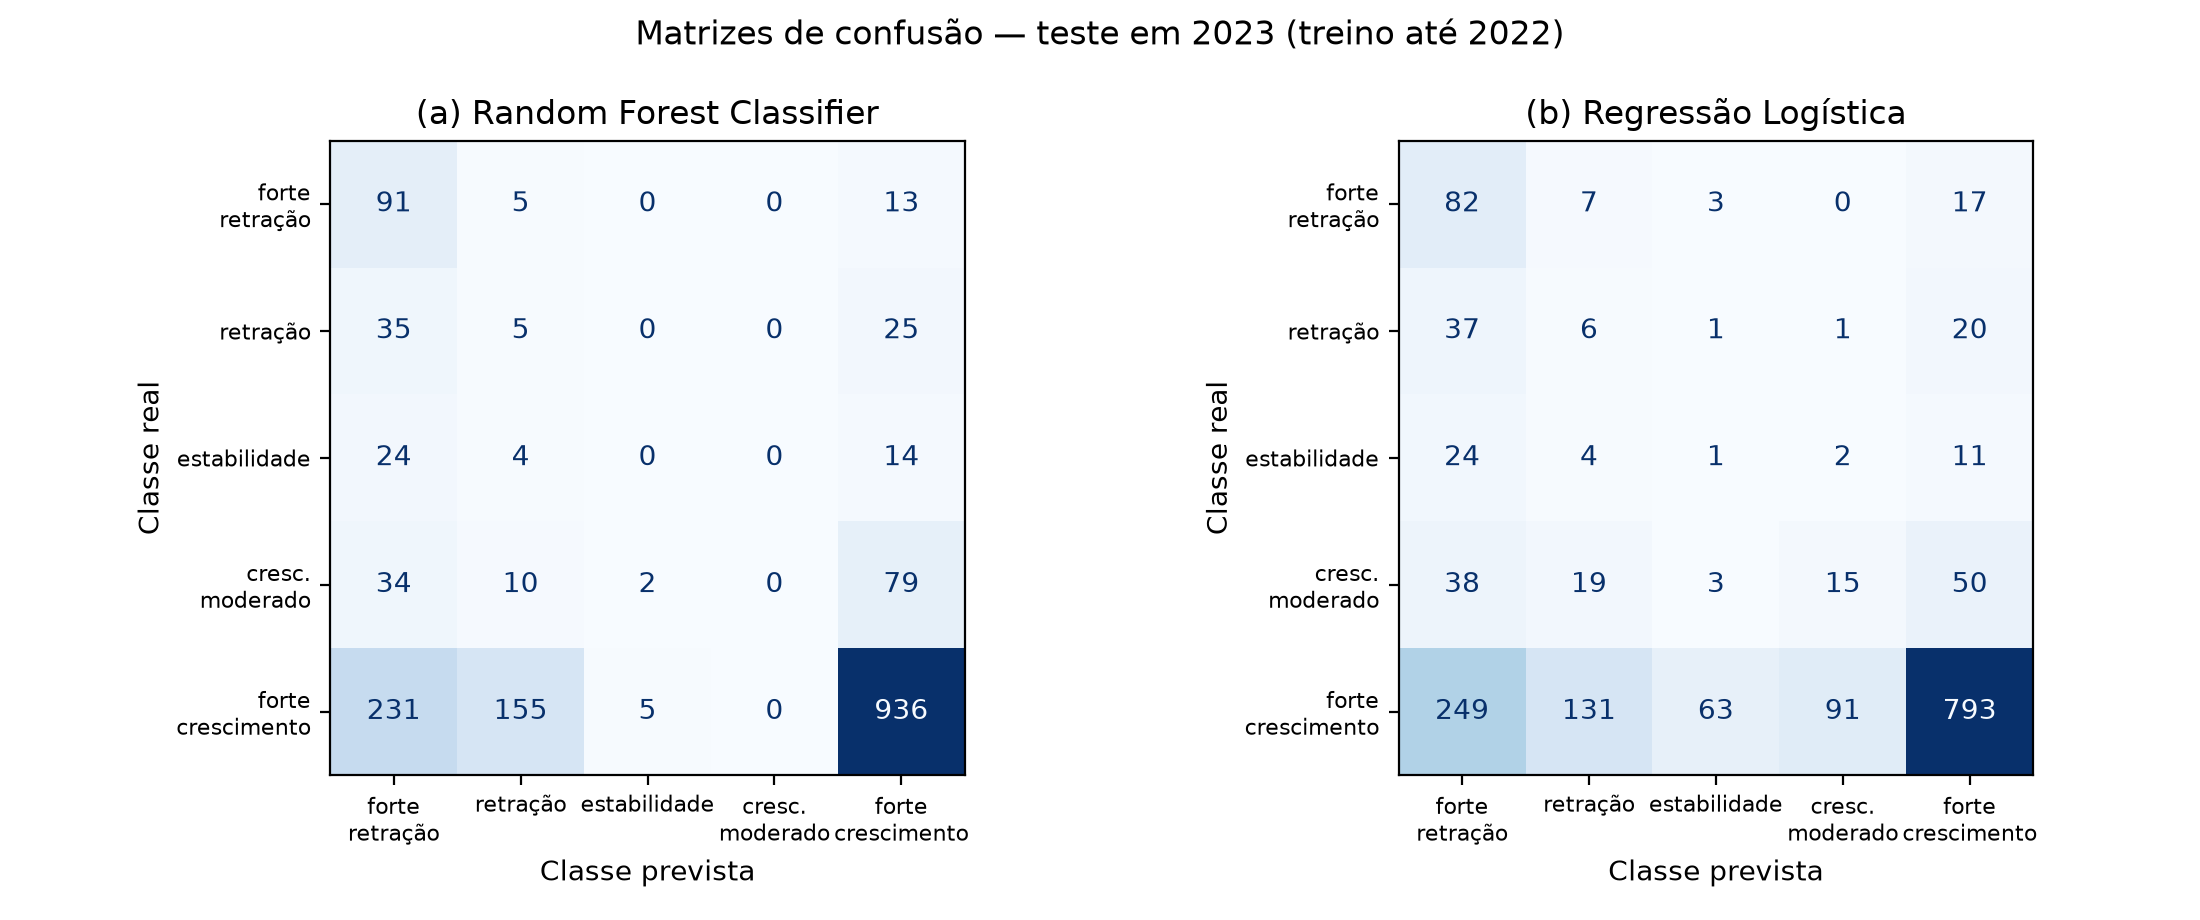

In [4]:
matriz_log = pd.read_csv(raiz / 'outputs/matriz_confusao_logistica_2023.csv', index_col=0)
rotulos = ['forte\nretração', 'retração', 'estabilidade', 'cresc.\nmoderado', 'forte\ncrescimento']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (titulo, m) in zip(axes, [('(a) Random Forest Classifier', resultado['matriz']),
                                   ('(b) Regressão Logística', matriz_log)]):
    ConfusionMatrixDisplay(m.loc[CLASSES, CLASSES].to_numpy(), display_labels=rotulos).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(titulo)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
fig.suptitle('Matrizes de confusão — teste em 2023 (treino até 2022)')
fig.tight_layout()
fig.savefig(FIG / 'fig_classificacao_2023.png', dpi=200)
plt.show()

O Random Forest acertou 936 dos 1.327 casos de forte crescimento e 91 dos 109 de forte retração. A precisão em forte retração foi de 0,219, contra 0,191 da logística. Teve cinco acertos em retração e nenhum em estabilidade ou crescimento moderado.

In [5]:
resultado['importancias'].head(10).round(4)

cresc_pib_lag1                0.1216
part_industria_ult            0.1082
cresc_pib_mediana_uf_lag1     0.0981
part_agro_ult                 0.0937
log_pib_per_capita_lag1       0.0922
part_servicos_ult             0.0891
cresc_pib_lag2                0.0568
log_producao_agricola_lag1    0.0550
log_pib_lag1                  0.0501
log_populacao_ult             0.0480
dtype: float64

A importância por impureza fica distribuída: o crescimento do PIB em t−1 lidera, seguido da estrutura setorial (participações da indústria, serviços e agropecuária), do PIB per capita e dos indicadores agropecuários. Isso é coerente com a EDA do Peter: as caudas de crescimento se concentram em municípios pequenos e dependentes de uma atividade. A importância por impureza favorece variáveis contínuas e não indica causalidade.

## 3. Comparação com a Regressão Logística e escolha do classificador final
`consolidar_previsoes.py` recalcula as métricas a partir das previsões por município dos dois modelos (verificando que ambos foram avaliados nos mesmos 1.668 municípios e rótulos reais) e aplica a regra definida antes da comparação: **maior F1 macro em 2023**.

In [6]:
from consolidar_previsoes import consolidar
consolidado = consolidar()
consolidado['comparacao_classificacao'].set_index('modelo').round(4).T

                          modelo     R2  MAPE_%
                Regressão Linear 0.9955 17.9357
         Random Forest Regressor 0.9985  8.9979
Referência (PIB_2023 = PIB_2022) 0.9874 13.4661
Regressão escolhida: Random Forest Regressor

                               modelo  f1_macro  f1_ponderado  acuracia
                  Regressão Logística    0.2434        0.6008    0.5378
             Random Forest Classifier    0.2341        0.6464    0.6187
Referência (sempre forte crescimento)    0.1772        0.7050    0.7956
Classificação escolhida: Regressão Logística

Concordância classe prevista x classe implícita no PIB previsto: 95.0%
previsoes_finais_2024.csv: 1668 municípios


modelo,Regressão Logística,Random Forest Classifier,Referência (sempre forte crescimento)
f1_macro,0.2434,0.2341,0.1772
f1_ponderado,0.6008,0.6464,0.7050
acuracia,0.5378,0.6187,0.7956
f1_forte retração,0.3043,0.3473,0.0000
f1_retração,0.0517,0.0410,0.0000
f1_estabilidade,0.0177,0.0000,0.0000
f1_crescimento moderado,0.1282,0.0000,0.0000
f1_forte crescimento,0.7151,0.7820,0.8861


**Decisão após a reexecução:** a Regressão Logística fornece as classes da entrega final pelo maior F1 macro (0,2434 contra 0,2341 do Random Forest). O Random Forest teve F1 ponderado de 0,6464 e acurácia de 0,6187, superiores aos da logística, mas esses indicadores dão mais peso à classe majoritária. Ambos têm baixo desempenho nas classes intermediárias.

Os resultados anteriores foram substituídos pelos obtidos com Python 3.12.14 e as versões fixadas em requirements.txt.

## 4. Consolidação das previsões de 2024
A regressão final segue a regra do menor MAPE em 2023: o Random Forest Regressor do Peter (MAPE 9,00%) supera a regressão linear selecionada (17,94%) e a referência ingênua (13,47%). O arquivo final tem uma linha por município com o PIB previsto, a classe prevista e as previsões alternativas de cada modelo.

In [7]:
consolidado['comparacao_regressao'].round(4)

,modelo,R2,MAPE_%
0,Regressão Linear,0.9955,17.9357
1,Random Forest Regressor,0.9985,8.9979
2,Referência (PIB_2023 = PIB_2022),0.9874,13.4661


In [8]:
final = consolidado['final']
print('PIB total do Sudeste (R$ trilhões): 2023 oficial =', round(final.pib_2023_oficial_mil_reais.sum() / 1e9, 3),
      '| 2024 previsto =', round(final.pib_previsto_2024_mil_reais.sum() / 1e9, 3))
final.head()

PIB total do Sudeste (R$ trilhões): 2023 oficial = 5.799 | 2024 previsto = 6.32


,codigo_municipio,municipio,uf,ano,pib_2023_oficial_mil_reais,pib_previsto_2024_mil_reais,variacao_prevista_pct,classe_prevista_2024,modelo_regressao,modelo_classificacao,pib_previsto_linear_mil_reais,pib_previsto_rf_mil_reais,classe_logistica,classe_rf,classe_implicita_regressao
0,3100104,Abadia dos Dourados,MG,2024,190396.516,229124.592,20.340748,forte crescimento,Random Forest Regressor,Regressão Logística,226775.789,229124.592,forte crescimento,forte crescimento,forte crescimento
1,3100203,Abaeté,MG,2024,641970.992,742237.916,15.618607,forte crescimento,Random Forest Regressor,Regressão Logística,709473.496,742237.916,forte crescimento,forte crescimento,forte crescimento
2,3100302,Abre Campo,MG,2024,331512.387,382078.903,15.253281,forte crescimento,Random Forest Regressor,Regressão Logística,377617.590,382078.903,forte crescimento,forte crescimento,forte crescimento
3,3100401,Acaiaca,MG,2024,85065.900,97690.186,14.840595,forte crescimento,Random Forest Regressor,Regressão Logística,114185.619,97690.186,forte crescimento,forte crescimento,forte crescimento
4,3100500,Açucena,MG,2024,172093.758,197513.791,14.771037,forte crescimento,Random Forest Regressor,Regressão Logística,207211.576,197513.791,forte crescimento,forte retração,forte crescimento


In [9]:
contagem = pd.DataFrame({
    'Random Forest Classifier (alternativo)': final.classe_rf.value_counts(),
    'Regressão Logística (final)': final.classe_logistica.value_counts(),
    'Implícita no PIB previsto (RF Regressor)': final.classe_implicita_regressao.value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
contagem

,Random Forest Classifier (alternativo),Regressão Logística (final),Implícita no PIB previsto (RF Regressor)
forte retração,322,42,9
retração,9,0,16
estabilidade,0,0,12
crescimento moderado,23,0,34
forte crescimento,1314,1626,1597


In [10]:
pd.crosstab(final.classe_prevista_2024, final.classe_implicita_regressao).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

classe_implicita_regressao,forte retração,retração,estabilidade,crescimento moderado,forte crescimento
classe_prevista_2024,,,,,
forte retração,6,5,5,8,18
retração,0,0,0,0,0
estabilidade,0,0,0,0,0
crescimento moderado,0,0,0,0,0
forte crescimento,3,11,7,26,1579


## 5. Limitações
- A classe escolhida coincide com a classe implícita no PIB previsto em 95,0% dos municípios. São previsões de tarefas diferentes, cuja divergência permanece no CSV final.
- A logística prevê apenas forte crescimento (1.626 municípios) e forte retração (42) para 2024. Os dois classificadores têm dificuldade com as classes intermediárias.
- O PIB é nominal, e a avaliação é retrospectiva por ano de referência.
- A reexecução alterou a configuração do Random Forest selecionada em 2022 e o classificador final. O ambiente usado nesta entrega está registrado no README e as versões estão fixadas em requirements.txt.